## Dependencies

In [1]:
%matplotlib inline

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
from IPython.display import display
from pdf2image import convert_from_path

In [3]:
import sys
sys.path.append('../libs')

%load_ext autoreload
%autoreload 2

import ios

## Setup

In [4]:
VERSION = 3
RANDOM_SEED = 1

VAR_X = ['mean', 'median', 'mode']
DIR = f'../../results/v{VERSION}/gender/predictions/comparison/rs{RANDOM_SEED}/regression/_<VAR_X>/*'
METRIC = 'test_rmse'

## Data

In [5]:
df_results_mean = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mean'))
df_results_median = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'median'))
df_results_mode = ios.load_json_files_to_dataframe(DIR.replace('<VAR_X>', 'mode'))
df_results = pd.concat([df_results_mean, df_results_median, df_results_mode], ignore_index=True)
df_results.shape

(1464, 20)

In [6]:
cols = ['y','features_id','features','train_eval','test_r2','test_rmse']
df_results[cols].sort_values(METRIC, ascending=True)

,y,features_id,features,train_eval,test_r2,test_rmse
834,mean,224,"[ngender_r, gender_w, gender_nw, single_char]",0.112366,0.824616,0.102887
849,mean,386,"[ngender_r, ngender_n, gender_n, gender_w, sin...",0.084598,0.824065,0.103048
145,mean,204,"[ngender_r, gender_n, gender_w, single_char]",0.096114,0.823217,0.103296
54,mean,505,"[ngender_r, gender_nw, mean_ngender_rw, mean_n...",0.092105,0.821156,0.103896
543,mean,476,"[ngender_r, gender_w, gender_nw, single_char, ...",0.109146,0.821084,0.103917
...,...,...,...,...,...,...
1303,median,28,"[gender_n, gender_nw]",0.221252,0.188283,0.265841
1364,median,2,[gender_n],0.240364,0.183801,0.266573
1162,median,3,[gender_w],0.246443,0.125758,0.275889
1460,median,35,"[gender_w, single_char]",0.234901,0.114733,0.277623


In [7]:
best_id = df_results[METRIC].idxmin()
best_id

834

In [8]:
df_results.loc[[best_id], ['y', 'features', 'train_eval','test_rmse','test_r2']]

,y,features,train_eval,test_rmse,test_r2
834,mean,"[ngender_r, gender_w, gender_nw, single_char]",0.112366,0.102887,0.824616


In [9]:
df_results.loc[best_id].features

# "['mean_ngender_rw', 'median_ngender_rw', 'mode_ngender_rw']"
# "['ngender_r', 'gender_w_female', 'gender_w_male', 'mean_ngender_rw']"

df_results.loc[best_id].features

['ngender_r', 'gender_w', 'gender_nw', 'single_char']

In [10]:
df_results.loc[best_id]

y                                                              mean
features_id                                                     224
features              [ngender_r, gender_w, gender_nw, single_char]
nfeatures                                                         4
cat_features                     [gender_w, gender_nw, single_char]
best_params       {'depth': 2, 'learning_rate': 0.1, 'l2_leaf_re...
best_score        {'learn': {'RMSE': 0.1123655394646891}, 'valid...
best_iteration                                                   95
test_size                                                       0.2
random_state                                                      1
loss_function                                                  RMSE
eval_metric                                                    RMSE
train_eval                                                 0.112366
test_r2                                                    0.824616
test_rmse                                       

In [11]:
metric = df_results.loc[best_id].y
f_name = DIR.replace('<VAR_X>',metric).replace('/*', "")
f_name = f"{f_name}/{df_results.loc[best_id].y}_{df_results.loc[best_id].features_id}"
f_name

'../../results/v3/gender/predictions/comparison/rs1/regression/_mean/mean_224'

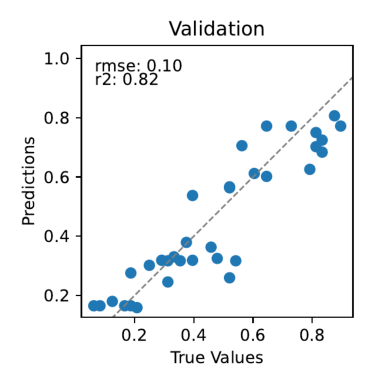

In [12]:
# predictions
fn = f"{f_name}_predictions_val.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



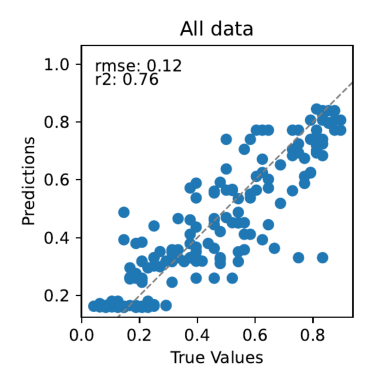

In [13]:
# predictions
fn = f"{f_name}_predictions_all.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



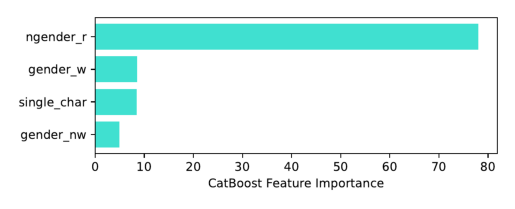

In [14]:
# predictions
fn = f"{f_name}_feature_importance.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()



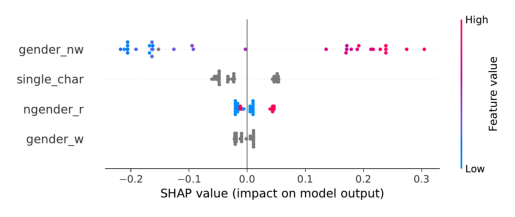

In [15]:
# predictions
fn = f"{f_name}_shap.pdf"
images = convert_from_path(fn)
plt.imshow(images[0])
plt.axis("off")  # Hide axes
plt.show()

